# Tutorial 1 — Sparse 2D sections to a high-resolution 3D field

This tutorial covers the complete NTF workflow: start from the full mouse-brain
simulation, aggregate selected input
sections into low-resolution bins, train NTF, and query expression at every
original high-resolution coordinate.

![Sparse, low-resolution sections to a high-resolution 3D field](../figures/super_resolution.jpg)

*NTF learns a continuous 3D field from sparse, low-resolution 2D sections and
supports sectioning at high-resolution coordinates.*

The mouse brain simulation data used here can be downloaded from [Zenodo](https://doi.org/10.5281/zenodo.19590993).

In [1]:
from pathlib import Path
import json
import os
import sys
import time

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import torch
from IPython.display import display
from scipy.stats import pearsonr, spearmanr
from skimage.metrics import structural_similarity

candidates = ([Path(os.environ["NTF_ROOT"])] if os.getenv("NTF_ROOT") else []) + [Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in candidates if (p / "NTF" / "train.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Set NTF_ROOT to the cloned NTF repository root.")
sys.path.insert(0, str(ROOT))

# try:
#     import mpmath
# except ImportError:
#     mpmath_wheel = ROOT / "mytrain/revision/experiment/simulation_mousebrain_100gene_rerun/environment/mpmath-1.3.0-py3-none-any.whl"
#     if not mpmath_wheel.is_file():
#         raise
#     for module_name in tuple(sys.modules):
#         if module_name == "mpmath" or module_name.startswith("mpmath."):
#             del sys.modules[module_name]
#     sys.path.insert(0, str(mpmath_wheel))
#     import mpmath

INPUT_PATH = Path(os.getenv(
    "NTF_SIMULATION_MOUSEBRAIN",
    ROOT / "mytrain/res/simulation/domain_interval/simulation_mousebrain_2000k.h5ad", # The mouse brain simulation data used here can be downloaded from https://doi.org/10.5281/zenodo.19590994.
)).resolve()
OUTPUT_DIR = Path(os.getenv(
    "NTF_TUTORIAL_OUTPUT",
    ROOT / "tutorial/outputs/01_simulation_reconstruction",
)).resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if not INPUT_PATH.is_file():
    raise FileNotFoundError(f"Simulation input not found: {INPUT_PATH}")
if not torch.cuda.is_available():
    raise RuntimeError("This full training tutorial requires a CUDA-capable GPU.")

DEVICE = "cuda:0"
N_ITER = 20000
SLICE_INTERVAL_K = 5
HIGH_RES_INTERVAL_M = 30
BIN_FACTOR = 8.0
QUERY_BATCH_SIZE = 8192
PLOT_SLICE_IDS = ["35", "45", "55"]
PLOT_GENE = "Gene_12_Diff"
run_start = time.time()
run_config = {
    "input_data": os.path.relpath(INPUT_PATH, ROOT),
    "output_dir": os.path.relpath(OUTPUT_DIR, ROOT),
    "device": DEVICE,
    "requested_training_iterations": N_ITER,
    "slice_interval_k": SLICE_INTERVAL_K,
    "high_res_interval_m": HIGH_RES_INTERVAL_M,
    "bin_factor": BIN_FACTOR,
    "query_batch_size": QUERY_BATCH_SIZE,
    "cached_results_used": False,
    "random_cell_sampling": False,
    "reference_sections_removed": False,
    "plot_point_thinning": False,
    "expression_normalization_for_plots": False,
    "3d_point_alpha": 0.35,
}
(OUTPUT_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2) + "\n")

print(f"Input: {os.path.relpath(INPUT_PATH, ROOT)}")
print(f"New outputs: {os.path.relpath(OUTPUT_DIR, ROOT)}")
print(f"Device: {DEVICE}; requested iterations: {N_ITER:,}")

Input: mytrain/res/simulation/domain_interval/simulation_mousebrain_2000k.h5ad
New outputs: tutorial/outputs/01_simulation_reconstruction
Device: cuda:0; requested iterations: 20,000


## 1. Load and verify the complete starting data

`X` contains normalize-total + log1p expression. The source object remains in
memory throughout input construction and full-coordinate reconstruction so all
unobserved sections remain available as ground truth.


In [2]:
simulation_data = ad.read_h5ad(INPUT_PATH)
simulation_data.obs["slice_id"] = simulation_data.obs["slice_id"].astype(str)
assert simulation_data.shape == (1975530, 100)
assert simulation_data.obs["slice_id"].nunique() == 100
assert set(simulation_data.obs["slice_id"]) == {str(i) for i in range(100)}
assert simulation_data.var_names[:90].str.endswith("_Diff").all()
assert simulation_data.var_names[90:].str.endswith("_HK").all()
assert simulation_data.var_names[90:].tolist() == [f"Gene_{i}_HK" for i in range(90, 100)]
assert simulation_data.obsm["spatial"].shape == (1975530, 3)
assert np.isfinite(np.asarray(simulation_data.X)).all()
assert np.isfinite(np.asarray(simulation_data.obsm["spatial"])).all()
assert PLOT_GENE in simulation_data.var_names

raw_coordinates = np.asarray(simulation_data.obsm["spatial"])
raw_bbox_size = np.ptp(raw_coordinates, axis=0).max()
spatial_scaling = 1.0 / raw_bbox_size if raw_bbox_size > 0 else 1.0
run_config.update({
    "input_observations": int(simulation_data.n_obs),
    "input_genes": int(simulation_data.n_vars),
    "input_sections": int(simulation_data.obs["slice_id"].nunique()),
    "spatial_scaling": float(spatial_scaling),
})
print(f"Loaded {simulation_data.n_obs:,} cells × {simulation_data.n_vars} genes")
print(f"Sections: {simulation_data.obs['slice_id'].nunique()}; spatial scaling: {spatial_scaling:.8f}")
display(pd.DataFrame({
    "property": ["cells", "genes", "sections", "HK genes", "coordinate dimensions"],
    "value": [simulation_data.n_obs, simulation_data.n_vars, simulation_data.obs["slice_id"].nunique(), 10, 3],
}))


Loaded 1,975,530 cells × 100 genes
Sections: 100; spatial scaling: 0.09249737


,property,value
0,cells,1975530
1,genes,100
2,sections,100
3,HK genes,10
4,coordinate dimensions,3


## 2. Construct the mixed-resolution training input from scratch

Every fifth section is observed, giving 20 input sections.  12,495
input observations are low-resolution bins generated with `bin_factor=8`.
Aggregation averages all cells within each spatial bin and uses their centroid
as the bin coordinate.

The other 80 sections are not removed from `simulation_data`; they remain
available for full reconstruction and evaluation.


### Helper functions

In [3]:
import numpy as np
import pandas as pd
import anndata
import scanpy as sc
from scipy.spatial import cKDTree

def calculate_avg_cell_distance(coords: np.ndarray) -> float:
    """Compute the average nearest-neighbour distance between cells."""
    if len(coords) < 2:
        return 1.0
    tree = cKDTree(coords)
    # Query k=2 neighbours; the first is the point itself, the second is the nearest neighbour
    dists, _ = tree.query(coords, k=2) 
    return np.mean(dists[:, 1])

def degrade_resolution(
    adata_slice: anndata.AnnData, 
    bin_factor: float = 2.0
) -> anndata.AnnData:
    """
    Reduce the spatial resolution of a single tissue slice.
    
    Args:
        adata_slice: AnnData object for a single slice.
        bin_factor: Grid cell size multiplier. 1.0 sets the grid size to approximately
                    the average inter-cell distance. 2.0 uses a grid whose edge length
                    is twice the average distance (roughly 4x area per bin).
    
    Returns:
        AnnData: Down-sampled data with fewer observations.
    """
    coords = adata_slice.obsm['spatial']
    
    if len(coords) == 0:
        return adata_slice
        
    # 1. Determine grid cell size
    avg_dist = calculate_avg_cell_distance(coords)
    grid_size = avg_dist * bin_factor
    
    # 2. Compute grid indices
    # Divide coordinates by grid_size and floor to obtain (ix, iy, iz) grid IDs.
    # Although slices are approximately 2D, we bin all three axes for generality.
    grid_indices = np.floor(coords / grid_size).astype(int)
    
    # 3. Aggregate cells within each grid bin
    df_coords = pd.DataFrame(grid_indices, columns=['gx', 'gy', 'gz'])
    df_coords['original_index'] = np.arange(len(coords))
    
    grouped = df_coords.groupby(['gx', 'gy', 'gz'])
    
    new_coords = []
    new_expr = []
    new_slice_ids = []
    
    raw_X = adata_slice.X
    if hasattr(raw_X, 'toarray'):
        raw_X = raw_X.toarray()
        
    raw_slice_ids = adata_slice.obs['slice_id'].values
    
    indices_groups = grouped.indices  # dict: grid_key -> array of original indices
    
    for grid_key, indices in indices_groups.items():
        # Coordinate: geometric centroid of cells in this bin
        cell_coords = coords[indices]
        centroid = np.mean(cell_coords, axis=0)
        new_coords.append(centroid)
        
        # Expression: mean across cells in the bin
        cell_expr = raw_X[indices]
        avg_expr = np.mean(cell_expr, axis=0)
        new_expr.append(avg_expr)
        
        # Slice ID: inherit from the first cell in the bin
        new_slice_ids.append(raw_slice_ids[indices[0]])
        
    if len(new_coords) == 0:
        return adata_slice[[]]  # return empty AnnData
        
    new_coords = np.array(new_coords)
    new_expr = np.array(new_expr)
    new_slice_ids = np.array(new_slice_ids)
    
    # 4. Build output AnnData
    new_adata = anndata.AnnData(X=new_expr)
    new_adata.obsm['spatial'] = new_coords
    new_adata.obs['slice_id'] = new_slice_ids
    new_adata.var_names = adata_slice.var_names
    new_adata.obs['resolution_type'] = 'low_res'
    new_adata.obs['bin_factor'] = bin_factor
    
    return new_adata

def create_mixed_resolution_dataset(
    adata_full: anndata.AnnData,
    slice_interval_k: int = 5,
    high_res_interval_m: int = 2,
    bin_factor: float = 2.0
) -> anndata.AnnData:
    """
    Assemble a mixed-resolution dataset.
    
    Args:
        adata_full: Full AnnData object containing all slices.
        slice_interval_k: Slice sampling interval (keep 1 slice every k slices).
        high_res_interval_m: Among the selected slices, retain every m-th slice at
                             full resolution; the rest are degraded.
                             Example: m=1 means all selected slices are high-res;
                                      m=2 alternates high / low.
        bin_factor: Resolution degradation factor for low-res slices.
    """
    # 1. Select slices
    all_slices = np.sort(adata_full.obs['slice_id'].unique().astype(int))
    selected_slice_ids = all_slices[::slice_interval_k].astype(str)
    
    subset_adata = adata_full[adata_full.obs['slice_id'].isin(selected_slice_ids)].copy()
    
    # 2. Process each selected slice
    processed_adatas = []
    
    sorted_ids = sorted(selected_slice_ids, key=lambda x: int(x))
    
    for idx, sid in enumerate(sorted_ids):
        slice_data = subset_adata[subset_adata.obs['slice_id'] == sid].copy()
        
        if ((idx + 1) % high_res_interval_m) == 0:
            # Keep at full resolution
            slice_data.obs['resolution_type'] = 'high_res'
            slice_data.obs['bin_factor'] = 1.0
            processed_adatas.append(slice_data)
        else:
            # Degrade to low resolution
            low_res_data = degrade_resolution(slice_data, bin_factor=bin_factor)
            processed_adatas.append(low_res_data)
            
    # 3. Concatenate all processed slices
    if not processed_adatas:
        return subset_adata  # fallback
        
    mixed_adata = anndata.concat(processed_adatas, join='outer')
    
    # Restore var metadata (may be lost during concat)
    mixed_adata.var = adata_full.var.copy()
    
    return mixed_adata

def build_mixed_resolution_input(simulation_data):

    raw_bbox_size = np.ptp(simulation_data.obsm["spatial"], axis=0).max()
    spatial_scaling = 1.0 / raw_bbox_size if raw_bbox_size > 0 else 1.0
    mixed = create_mixed_resolution_dataset(
        simulation_data,
        slice_interval_k=SLICE_INTERVAL_K,
        high_res_interval_m=HIGH_RES_INTERVAL_M,
        bin_factor=BIN_FACTOR,
    )
    mixed.obsm["spatial"] = np.asarray(mixed.obsm["spatial"]) * spatial_scaling
    return mixed, spatial_scaling

### Create low resolution, sparse input data

In [4]:
preprocessing_start = time.time()
train_data = create_mixed_resolution_dataset(
    simulation_data,
    slice_interval_k=SLICE_INTERVAL_K,
    high_res_interval_m=HIGH_RES_INTERVAL_M,
    bin_factor=BIN_FACTOR,
)
train_data.obsm["spatial"] = np.asarray(train_data.obsm["spatial"]) * spatial_scaling
train_data.obs["slice_id"] = train_data.obs["slice_id"].astype(str)
expected_observed_sections = {str(i) for i in range(0, 100, SLICE_INTERVAL_K)}
assert train_data.shape == (12495, 100)
assert set(train_data.obs["slice_id"]) == expected_observed_sections
assert train_data.obs["slice_id"].nunique() == 20
assert np.isfinite(np.asarray(train_data.X)).all()
assert np.isfinite(np.asarray(train_data.obsm["spatial"])).all()

train_path = OUTPUT_DIR / "mixed_resolution_input.h5ad"
train_data.write_h5ad(train_path, compression="gzip")
resolution_counts = train_data.obs.groupby("resolution_type", observed=True).size()
run_config.update({
    "training_observations": int(train_data.n_obs),
    "training_genes": int(train_data.n_vars),
    "observed_sections": int(train_data.obs["slice_id"].nunique()),
    "high_resolution_observations": int(resolution_counts.get("high_res", 0)),
    "low_resolution_bins": int(resolution_counts.get("low_res", 0)),
    "preprocessing_seconds": float(time.time() - preprocessing_start),
})
print(f"New training input: {train_data.shape[0]:,} observations × {train_data.shape[1]} genes")
print(f"Observed sections: {train_data.obs['slice_id'].nunique()}; source sections retained: {simulation_data.obs['slice_id'].nunique()}")
display(resolution_counts.rename("observations").to_frame())


/home/gongyuqiao/.conda/envs/ntf/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


New training input: 12,495 observations × 100 genes
Observed sections: 20; source sections retained: 100


,observations
resolution_type,
low_res,12495


## 3. Train NTF from the newly constructed input

This is a 20,000-iteration-configuration training run using the standard
`NTF.train` API. Model defaults, including early stopping, are unchanged. 


In [5]:
from NTF.config import add_shared_args, process_args
from NTF.train import train

parser = add_shared_args(description="Full mouse-brain mixed-resolution tutorial")
args = parser.parse_args([
    "--input_data", str(INPUT_PATH),
    "--output_dir", str(OUTPUT_DIR),
    "--log_dir", str(OUTPUT_DIR / "runs"),
    "--slice_id", "slice_id",
    "--n_iter", str(N_ITER),
    "--device", DEVICE,
])
args = process_args(args)
training_start = time.time()
model_wrapper = train(train_data, args)
training_seconds = time.time() - training_start
trained_inr_path = OUTPUT_DIR / "trained_inr.pt"
torch.save(model_wrapper.inr.state_dict(), trained_inr_path)
run_config.update({
    "training_seconds": float(training_seconds),
    "trained_inr": trained_inr_path.name,
    "early_stopping_checkpoint_present": (OUTPUT_DIR / "best_model.pth").is_file(),
})
print(f"Training wall time: {training_seconds / 60:.2f} minutes")
print(f"Saved new final INR state: {trained_inr_path}")


Training NeuralTranscriptomicField:   0%|          | 0/20000 [00:00<?, ?it/s]

/home/gongyuqiao/.conda/envs/ntf/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:192: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


Iter: 600, Loss: 1811.812540, Best: 1811.812540, Patience: 0/5
Iter: 800, Loss: 1787.534015, Best: 1787.534015, Patience: 0/5
Iter: 1000, Loss: 1751.431012, Best: 1751.431012, Patience: 0/5
Iter: 1200, Loss: 1703.833198, Best: 1703.833198, Patience: 0/5
Iter: 1400, Loss: 1646.868224, Best: 1646.868224, Patience: 0/5
Iter: 1600, Loss: 1582.961369, Best: 1582.961369, Patience: 0/5
Iter: 1800, Loss: 1515.073245, Best: 1515.073245, Patience: 0/5
Iter: 2000, Loss: 1445.670779, Best: 1445.670779, Patience: 0/5
Iter: 2200, Loss: 1376.544356, Best: 1376.544356, Patience: 0/5
Iter: 2400, Loss: 1308.669997, Best: 1308.669997, Patience: 0/5
Iter: 2600, Loss: 1241.943426, Best: 1241.943426, Patience: 0/5
Iter: 2800, Loss: 1175.718463, Best: 1175.718463, Patience: 0/5
Iter: 3000, Loss: 1109.545309, Best: 1109.545309, Patience: 0/5
Iter: 3200, Loss: 1043.092245, Best: 1043.092245, Patience: 0/5
Iter: 3400, Loss: 976.414487, Best: 976.414487, Patience: 0/5
Iter: 3600, Loss: 910.424723, Best: 910.4247

## 4. Reconstruct every original high-resolution coordinate

`sample_points` queries all 1,975,530 source coordinates. The new reconstruction
keeps the original 100-gene `X` as ground truth and stores the new NTF output in
`layers['prediction']`.


In [6]:
from NTF.sample import sample_points

query_start = time.time()
query_coordinates = torch.from_numpy(raw_coordinates * spatial_scaling).float().to(DEVICE)
prediction_result = sample_points(model_wrapper.inr, query_coordinates, batch_size=QUERY_BATCH_SIZE)
prediction = prediction_result["expression"].cpu().numpy()
query_seconds = time.time() - query_start
assert prediction.shape == (1975530, 100)
assert np.isfinite(prediction).all()
assert not np.array_equal(prediction, np.asarray(simulation_data.X))

reconstruction = ad.AnnData(
    X=np.asarray(simulation_data.X).copy(),
    obs=simulation_data.obs.copy(),
    var=pd.DataFrame(index=simulation_data.var_names.copy()),
)
reconstruction.obsm["spatial"] = raw_coordinates.copy()
reconstruction.layers["prediction"] = prediction
assert reconstruction.obs_names.equals(simulation_data.obs_names)
assert np.array_equal(reconstruction.obsm["spatial"], simulation_data.obsm["spatial"])
assert set(reconstruction.obs["slice_id"]) == {str(i) for i in range(100)}
run_config.update({
    "reconstruction_observations": int(reconstruction.n_obs),
    "reconstruction_genes": int(reconstruction.n_vars),
    "reconstruction_sections": int(reconstruction.obs["slice_id"].nunique()),
    "query_seconds": float(query_seconds),
})
print(f"New prediction: {prediction.shape[0]:,} cells × {prediction.shape[1]} genes")
print(f"Prediction covers {reconstruction.obs['slice_id'].nunique()} sections; query time: {query_seconds / 60:.2f} minutes")
del prediction_result, query_coordinates
if torch.cuda.is_available():
    torch.cuda.empty_cache()


New prediction: 1,975,530 cells × 100 genes
Prediction covers 100 sections; query time: 0.01 minutes


## 5. Recompute all metrics from the new prediction

Pearson correlation, Spearman correlation, RMSE and 3D SSIM are computed for all
100 genes using every cell. The per-gene table retains all genes and labels the
90 Diff / 10 HK groups. Only the 90 Diff genes enter the overall evaluation. HK genes remain excluded from the overall metric mean
because their random cell-level noise is not a reconstructable spatial signal.


In [7]:
def safe_correlation(function, truth, predicted):
    if np.std(truth) == 0 or np.std(predicted) == 0:
        return np.nan
    return float(function(truth, predicted).statistic)


def calculate_3d_ssim(truth, predicted, coordinates):
    grid_dimensions = coordinates.astype(int).max(axis=0) + 1
    minimum_dimension = int(min(grid_dimensions))
    window_size = minimum_dimension if minimum_dimension % 2 else minimum_dimension - 1
    if window_size < 3:
        return np.nan, grid_dimensions, window_size
    truth_volume = np.zeros(grid_dimensions, dtype=np.float64)
    prediction_volume = np.zeros(grid_dimensions, dtype=np.float64)
    integer_coordinates = coordinates.astype(int)
    x = integer_coordinates[:, 0]
    y = integer_coordinates[:, 1]
    z = integer_coordinates[:, 2]
    truth_volume[x, y, z] = truth
    prediction_volume[x, y, z] = predicted
    data_range = max(truth_volume.max(), prediction_volume.max()) - min(truth_volume.min(), prediction_volume.min())
    score = 1.0 if data_range == 0 else structural_similarity(
        truth_volume,
        prediction_volume,
        data_range=data_range,
        win_size=window_size,
    )
    return float(score), grid_dimensions, window_size


metrics_start = time.time()
truth_matrix = np.asarray(reconstruction.X)
prediction_matrix = np.asarray(reconstruction.layers["prediction"])
pearson_values = []
spearman_values = []
ssim_values = []
grid_dimensions = None
ssim_window_size = None
for gene_index in range(reconstruction.n_vars):
    truth = truth_matrix[:, gene_index]
    predicted = prediction_matrix[:, gene_index]
    pearson_values.append(safe_correlation(pearsonr, truth, predicted))
    spearman_values.append(safe_correlation(spearmanr, truth, predicted))
    ssim_score, grid_dimensions, ssim_window_size = calculate_3d_ssim(truth, predicted, raw_coordinates)
    ssim_values.append(ssim_score)
    if (gene_index + 1) % 10 == 0 or gene_index + 1 == reconstruction.n_vars:
        print(f"Metrics calculated for {gene_index + 1}/{reconstruction.n_vars} genes")

reconstruction.var["pearson_corr"] = pearson_values
reconstruction.var["spearman_corr"] = spearman_values
reconstruction.var["rmse"] = np.sqrt(np.mean((truth_matrix - prediction_matrix) ** 2, axis=0))
reconstruction.var["ssim_3d"] = ssim_values
reconstruction.var["gene_group"] = ["Diff"] * 90 + ["HK"] * 10
reconstruction.var["included_in_overall"] = reconstruction.var["gene_group"] == "Diff"
gene_metrics = reconstruction.var[["gene_group", "included_in_overall", "pearson_corr", "spearman_corr", "rmse", "ssim_3d"]].copy()
gene_metrics.index.name = "gene"
gene_metrics = gene_metrics.reset_index()
overall_gene_metrics = gene_metrics.loc[gene_metrics["included_in_overall"]]
summary = overall_gene_metrics[["pearson_corr", "spearman_corr", "rmse", "ssim_3d"]].mean().to_frame().T
summary.insert(0, "evaluation", "new NTF run; overall mean over 90 Diff genes only (10 HK excluded); all 1,975,530 cells; all 100 sections")
metrics_seconds = time.time() - metrics_start

gene_metrics.to_csv(OUTPUT_DIR / "gene_metrics.csv", index=False)
summary.to_csv(OUTPUT_DIR / "metrics_summary.csv", index=False)
reconstruction_path = OUTPUT_DIR / "reconstruction.h5ad"
reconstruction.write_h5ad(reconstruction_path, compression="gzip")
run_config.update({
    "metrics_seconds": float(metrics_seconds),
    "ssim_grid_dimensions": np.asarray(grid_dimensions).tolist(),
    "ssim_window_size": int(ssim_window_size),
    "reconstruction_file": reconstruction_path.name,
    "overall_evaluation_genes": 90,
    "excluded_HK_genes": 10,
})
print(f"SSIM grid: {grid_dimensions}; window: {ssim_window_size}; metric time: {metrics_seconds:.2f} seconds")
print(f"Saved new reconstruction: {reconstruction_path}")
display(gene_metrics.round(4))
display(summary.round(4))


Metrics calculated for 10/100 genes
Metrics calculated for 20/100 genes
Metrics calculated for 30/100 genes
Metrics calculated for 40/100 genes
Metrics calculated for 50/100 genes
Metrics calculated for 60/100 genes
Metrics calculated for 70/100 genes
Metrics calculated for 80/100 genes
Metrics calculated for 90/100 genes
Metrics calculated for 100/100 genes
SSIM grid: [ 8  6 12]; window: 5; metric time: 63.20 seconds
Saved new reconstruction: /mnt/experiments/gongyq/analysis_link/ur_annotation/NTF/tutorial/outputs/01_simulation_reconstruction/reconstruction.h5ad


,gene,gene_group,included_in_overall,pearson_corr,spearman_corr,rmse,ssim_3d
0,Gene_0_Diff,Diff,True,0.6270,0.5354,1.9379,0.5125
1,Gene_1_Diff,Diff,True,0.6122,0.5204,1.9792,0.5874
2,Gene_2_Diff,Diff,True,0.5866,0.4824,1.9105,0.5710
3,Gene_3_Diff,Diff,True,0.6660,0.6782,1.5807,0.5854
4,Gene_4_Diff,Diff,True,0.7215,0.6830,1.5740,0.6305
...,...,...,...,...,...,...,...
95,Gene_95_HK,HK,False,-0.0002,-0.0060,1.6840,0.5292
96,Gene_96_HK,HK,False,-0.0014,-0.0064,1.6830,0.5285
97,Gene_97_HK,HK,False,-0.0007,-0.0063,1.6819,0.5197
98,Gene_98_HK,HK,False,-0.0007,-0.0063,1.6810,0.5125


,evaluation,pearson_corr,spearman_corr,rmse,ssim_3d
0,new NTF run; overall mean over 90 Diff genes o...,0.6406,0.5666,1.781,0.5913


## 6. Inspect the ten HK noise controls

HK genes contain non-zero random expression without a spatial pattern. Thus,
“no false positives” does **not** mean zero expression or a high correlation
with unpredictable noise. It means NTF should not invent coherent hotspots or
other localized spatial patterns. A smooth non-zero background is acceptable.

The table uses every cell and compares truth/prediction means, variability and
the range of all 100 section means. The raw-expression maps then inspect every
HK gene on section 45.


,gene,truth_mean,prediction_mean,truth_std,prediction_std,truth_section_mean_min,truth_section_mean_max,prediction_section_mean_min,prediction_section_mean_max,prediction_section_mean_range
0,Gene_90_HK,4.3849,4.3872,1.6788,0.1366,4.3463,4.4865,4.2547,4.4935,0.2389
1,Gene_91_HK,4.3836,4.3765,1.6796,0.1315,4.3351,4.5089,4.2426,4.4818,0.2393
2,Gene_92_HK,4.3842,4.3722,1.6794,0.1625,4.3311,4.5198,4.2418,4.4800,0.2382
3,Gene_93_HK,4.3824,4.3801,1.6791,0.1240,4.3400,4.4914,4.2471,4.4857,0.2386
4,Gene_94_HK,4.3810,4.3735,1.6806,0.1239,4.3260,4.5240,4.2406,4.4786,0.2379
5,Gene_95_HK,4.3836,4.3791,1.6791,0.1444,4.3426,4.5156,4.2473,4.4861,0.2388
6,Gene_96_HK,4.3843,4.3897,1.6792,0.1302,4.3191,4.4861,4.2540,4.4959,0.2419
7,Gene_97_HK,4.3850,4.3834,1.6789,0.1217,4.3384,4.5001,4.2474,4.4887,0.2414
8,Gene_98_HK,4.3836,4.3862,1.6781,0.1181,4.3322,4.5168,4.2527,4.4914,0.2388
9,Gene_99_HK,4.3814,4.3857,1.6811,0.1420,4.3387,4.4903,4.2508,4.4922,0.2414


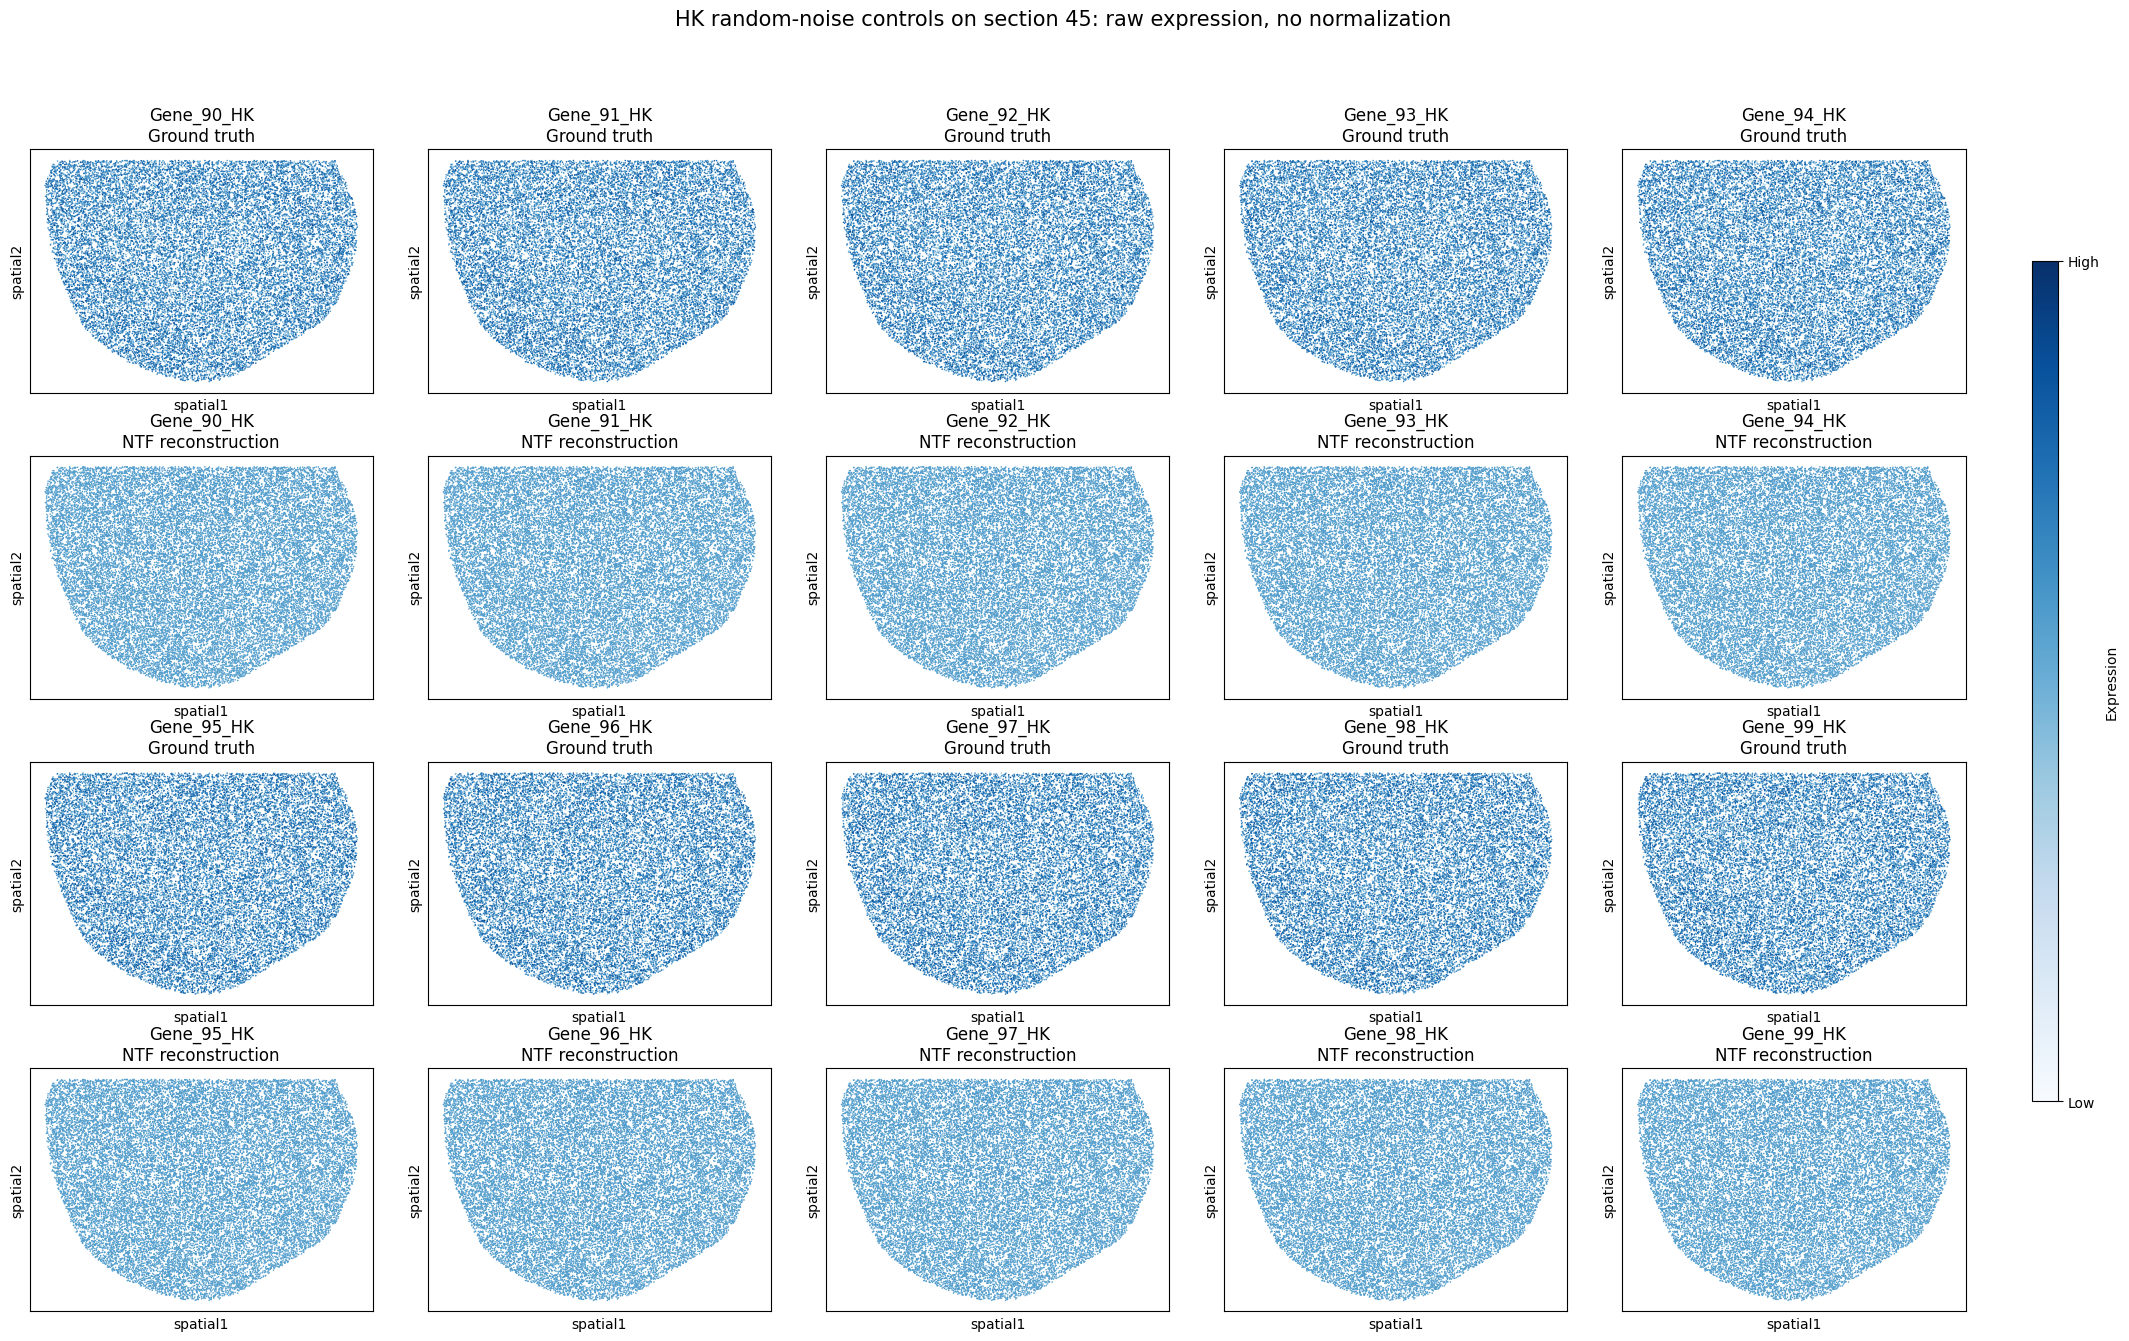

In [8]:
hk_gene_names = reconstruction.var_names[reconstruction.var["gene_group"] == "HK"].tolist()
section_numbers = reconstruction.obs["slice_id"].astype(int).to_numpy()
section_counts = np.bincount(section_numbers, minlength=100)
hk_rows = []
for gene_name in hk_gene_names:
    gene_index = reconstruction.var_names.get_loc(gene_name)
    truth = truth_matrix[:, gene_index]
    predicted = prediction_matrix[:, gene_index]
    truth_section_means = np.bincount(section_numbers, weights=truth, minlength=100) / section_counts
    prediction_section_means = np.bincount(section_numbers, weights=predicted, minlength=100) / section_counts
    hk_rows.append({
        "gene": gene_name,
        "truth_mean": float(np.mean(truth)),
        "prediction_mean": float(np.mean(predicted)),
        "truth_std": float(np.std(truth)),
        "prediction_std": float(np.std(predicted)),
        "truth_section_mean_min": float(np.min(truth_section_means)),
        "truth_section_mean_max": float(np.max(truth_section_means)),
        "prediction_section_mean_min": float(np.min(prediction_section_means)),
        "prediction_section_mean_max": float(np.max(prediction_section_means)),
        "prediction_section_mean_range": float(np.ptp(prediction_section_means)),
    })
hk_diagnostics = pd.DataFrame(hk_rows)
hk_diagnostics.to_csv(OUTPUT_DIR / "hk_diagnostics.csv", index=False)
display(hk_diagnostics.round(4))

hk_section = reconstruction[reconstruction.obs["slice_id"] == "45", hk_gene_names].copy()
hk_truth_values = np.asarray(hk_section.X).ravel()
hk_prediction_values = np.asarray(hk_section.layers["prediction"]).ravel()
hk_expression_min = min(hk_truth_values.min(), hk_prediction_values.min())
hk_expression_max = max(hk_truth_values.max(), hk_prediction_values.max())
fig, axes = plt.subplots(4, 5, figsize=(22, 14))
for column in range(5):
    for gene_offset in range(2):
        gene_name = hk_gene_names[gene_offset * 5 + column]
        for prediction_row, (layer, title) in enumerate([(None, "Ground truth"), ("prediction", "NTF reconstruction")]):
            row = gene_offset * 2 + prediction_row
            sc.pl.embedding(
                hk_section,
                basis="spatial",
                color=gene_name,
                layer=layer,
                title=f"{gene_name}\n{title}",
                ax=axes[row, column],
                show=False,
                cmap="Blues",
                vmin=hk_expression_min,
                vmax=hk_expression_max,
                colorbar_loc=None,
            )
fig.suptitle("HK random-noise controls on section 45: raw expression, no normalization", fontsize=15)
fig.subplots_adjust(left=0.03, right=0.91, bottom=0.05, top=0.88, wspace=0.16, hspace=0.26)
hk_mappable = plt.cm.ScalarMappable(cmap="Blues")
hk_mappable.set_clim(hk_expression_min, hk_expression_max)
hk_colorbar = fig.colorbar(hk_mappable, cax=fig.add_axes([0.94, 0.20, 0.012, 0.60]), label="Expression")
hk_colorbar.set_ticks([hk_expression_min, hk_expression_max], labels=["Low", "High"])
display(fig)
plt.close(fig)


## 7. Compare complete 2D sections from the new run

Sections 35, 45 and 55 show every high-resolution reference cell, every actual
input observation and every newly reconstructed cell for `Gene_12_Diff`.


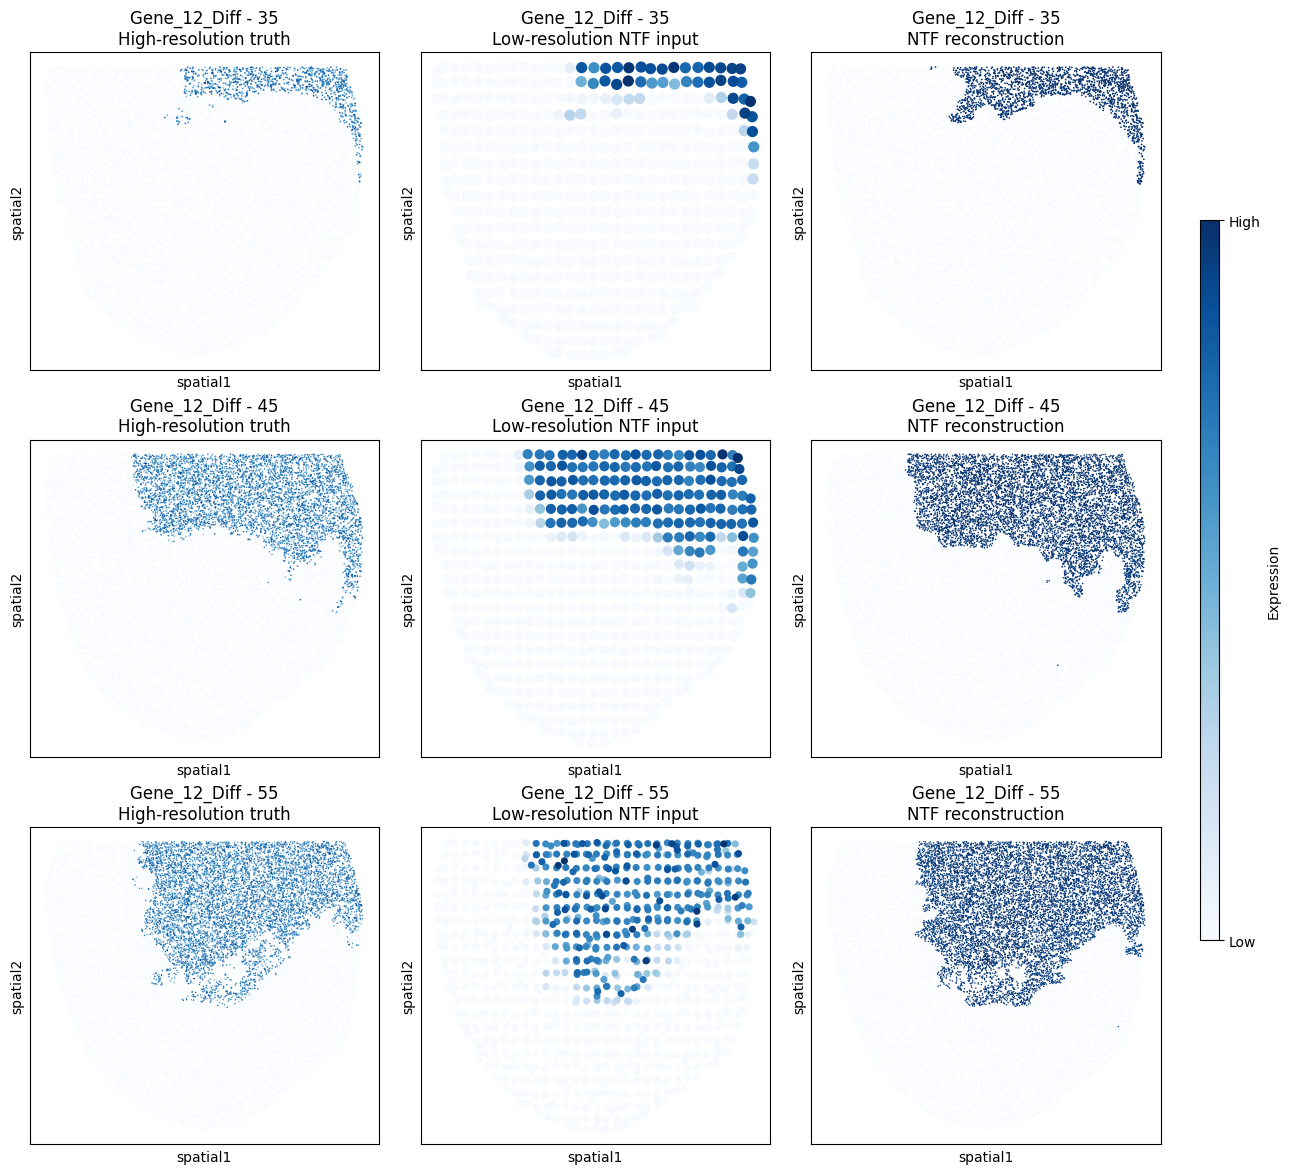

In [9]:
reconstruction_gene = reconstruction[:, [PLOT_GENE]].copy()
train_values = np.asarray(train_data[:, PLOT_GENE].X).ravel()
truth_values = np.asarray(reconstruction_gene.X).ravel()
prediction_values = np.asarray(reconstruction_gene.layers["prediction"]).ravel()
expression_min = min(train_values.min(), truth_values.min(), prediction_values.min())
expression_max = max(train_values.max(), truth_values.max(), prediction_values.max())


def add_low_high_colorbar(fig, rect):
    colorbar_ax = fig.add_axes(rect)
    mappable = plt.cm.ScalarMappable(cmap="Blues")
    mappable.set_clim(expression_min, expression_max)
    colorbar = fig.colorbar(mappable, cax=colorbar_ax, label="Expression")
    colorbar.set_ticks([expression_min, expression_max], labels=["Low", "High"])


def plot_sub_slice(adata, slice_id, gene_name, layer=None, show=False, ax=None, title=None):
    subset = adata[adata.obs["slice_id"] == slice_id].copy()
    sc.pl.embedding(
        subset,
        basis="spatial",
        color=gene_name,
        title=title or f"{PLOT_GENE} - {slice_id}",
        layer=layer,
        show=show,
        ax=ax,
        cmap="Blues",
        colorbar_loc=None,
    )


fig, axes = plt.subplots(len(PLOT_SLICE_IDS), 3, figsize=(13, 12))
for row, section_id in enumerate(PLOT_SLICE_IDS):
    columns = [
        (reconstruction_gene, None, "High-resolution truth"),
        (train_data, None, "Low-resolution NTF input"),
        (reconstruction_gene, "prediction", "NTF reconstruction"),
    ]
    for column, (data, layer, title) in enumerate(columns):
        plot_sub_slice(
            data,
            section_id,
            PLOT_GENE,
            layer=layer,
            ax=axes[row, column],
            title=f"{PLOT_GENE} - {section_id}\n{title}",
        )
fig.subplots_adjust(left=0.03, right=0.90, bottom=0.03, top=0.94, wspace=0.12, hspace=0.22)
add_low_high_colorbar(fig, [0.93, 0.20, 0.015, 0.60])
display(fig)
plt.close(fig)
